# CC3045 Deep Learning — Laboratorio 9: VAE y Difusión sobre Fashion-MNIST
**Semilla aleatoria: 42** (se fija en todas las celdas de entrenamiento y muestreo).

**Uso de IA generativa:** se usó Claude Code (asistente de IA) para estructurar el código y el notebook. Prompt utilizado:
> *"Actúa como apoyo técnico para mi Laboratorio 9 de Deep Learning. Te compartiré mi lógica, algoritmos en pseudocódigo y código existente. Ayúdame a revisar mis propuestas y convertirlas en código estructurado, manteniendo mis decisiones cuando sean correctas.

Quiero que:
1. Analices mi lógica e identifiques errores, ambigüedades o pasos faltantes. Explica los problemas antes de proponer cambios.
2. Transformes mis algoritmos en funciones claras de Python con PyTorch, con parámetros, retornos y nombres descriptivos.
3. Identifiques las funciones auxiliares que me faltan y generes las necesarias para integrar mi propuesta. Explica qué hace cada una y por qué se necesita.
4. Reutilices mi código y evites duplicar funciones o cambiar la arquitectura sin justificación.
5. Comentes el código para relacionar las operaciones con mi algoritmo y las fórmulas del laboratorio. Indica las dimensiones esperadas de los tensores cuando sea relevante.
6. Sugieras comprobaciones sencillas para verificar formas, rangos y resultados numéricos.
7. Si falta una decisión importante, me preguntes antes de implementarla.

Trabaja únicamente sobre la task y los algoritmos que te comparta. No generes el laboratorio completo, no inventes resultados y no redactes conclusiones experimentales sin mis datos."*

*Por qué funcionó:* el prompt apunta al enunciado completo (que contiene fórmulas, hiperparámetros y entregables explícitos), por lo que el asistente pudo traducir cada Task a código verificable. Todo el código está escrito con tensores de PyTorch (sin `diffusers`, sin `kl_divergence`, sin calendarios prefabricados) y todos los números del análisis salen de las ejecuciones de este notebook.

In [1]:
import os, math, time, json, random, copy
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

SEED = 42
FAST = os.environ.get("LAB9_FAST") == "1"          # modo de prueba rapida (no usar para entregar)
CK  = "ckpt_fast" if FAST else "ckpt"               # checkpoints (permiten reanudar)
FIG = "figs_fast" if FAST else "figs"
os.makedirs(CK, exist_ok=True); os.makedirs(FIG, exist_ok=True)
torch.set_num_threads(int(os.environ.get("LAB9_THREADS", os.cpu_count())))
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed()
R = {}   # diccionario con todos los resultados numericos
CLASSES = ["Camiseta","Pantalon","Sueter","Vestido","Abrigo","Sandalia","Camisa","Tenis","Bolso","Botin"]

def show(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=110); plt.show()

def to_grid(imgs, nrow, pad=1, lo=0., hi=1.):
    # imgs [N,1,28,28] en [lo,hi] -> mosaico numpy en [0,1]
    a = ((imgs.detach().clamp(lo, hi) - lo) / (hi - lo)).squeeze(1).cpu().numpy()
    N = len(a); ncol = math.ceil(N / nrow)
    cv = np.ones((nrow*(28+pad)+pad, ncol*(28+pad)+pad))
    for k, im in enumerate(a):
        r, c = divmod(k, ncol)
        cv[pad+r*(28+pad):pad+r*(28+pad)+28, pad+c*(28+pad):pad+c*(28+pad)+28] = im
    return cv

def sharpness(x):
    # nitidez = media de |x[i,j+1]-x[i,j]| (pixeles horizontalmente adyacentes); x [N,1,28,28]
    return (x[..., 1:] - x[..., :-1]).abs().mean().item()

# ---- Task 1.1: datos ----
tr = datasets.FashionMNIST("data", train=True, download=True)
X = tr.data.float().div(255).unsqueeze(1)           # [60000,1,28,28] en [0,1]
Y = tr.targets.clone()
Xtr, Ytr = X[:-5000], Y[:-5000]                     # 55 000 entrenamiento
Xva, Yva = X[-5000:], Y[-5000:]                     # ultimos 5 000 -> validacion
if FAST: Xtr, Ytr = Xtr[:2560], Ytr[:2560]          # subconjunto solo en modo de prueba
batch_size, latent_dim, epochs, lr = 128, 2, 20, 1e-3
beta_values = [0.1, 1.0, 10.0]
EP_VAE = 2 if FAST else epochs
print(Xtr.shape, Xva.shape, "semilla", SEED, "FAST" if FAST else "")

torch.Size([55000, 1, 28, 28]) torch.Size([5000, 1, 28, 28]) semilla 42 


## Task 1 — VAE

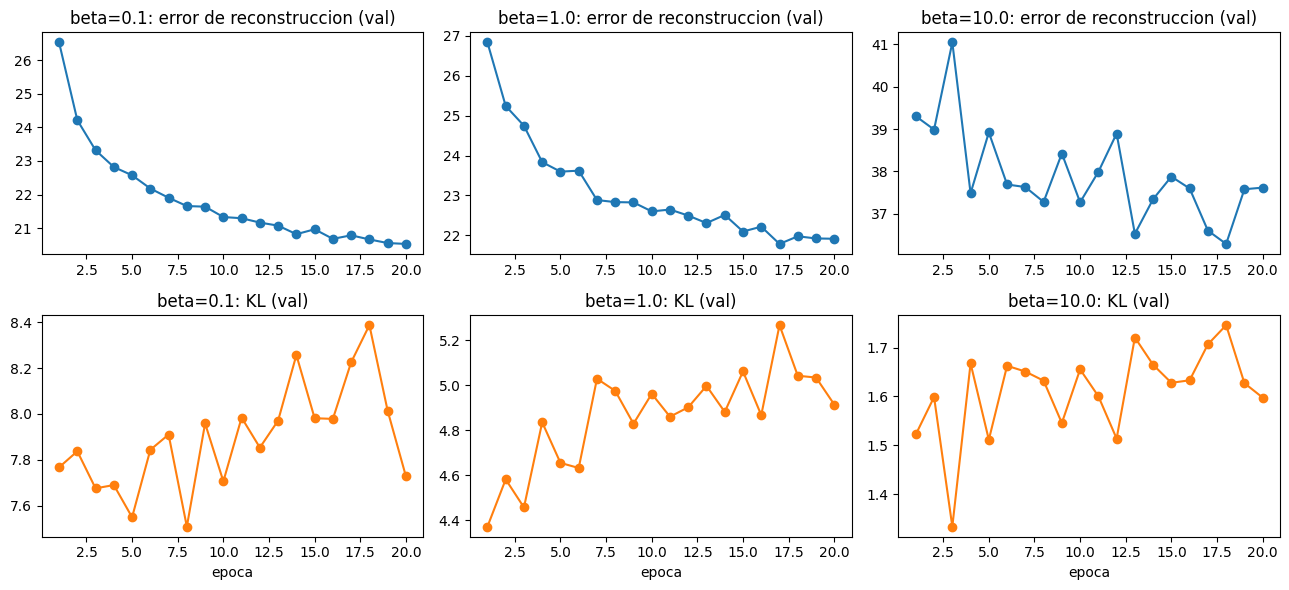

In [2]:
# ---- Task 1.2: VAE (misma arquitectura para todo beta) ----
class VAE(nn.Module):
    def __init__(self, zd=latent_dim):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1,32,4,2,1), nn.ReLU(), nn.Conv2d(32,64,4,2,1), nn.ReLU(),
                                 nn.Flatten(), nn.Linear(64*7*7,256), nn.ReLU(), nn.Linear(256, 2*zd))
        self.dec = nn.Sequential(nn.Linear(zd,256), nn.ReLU(), nn.Linear(256,64*7*7), nn.ReLU(),
                                 nn.Unflatten(1,(64,7,7)), nn.ConvTranspose2d(64,32,4,2,1), nn.ReLU(),
                                 nn.ConvTranspose2d(32,1,4,2,1), nn.Sigmoid())
    def encode(self, x):
        mu, logvar = self.enc(x).chunk(2, dim=1)       # mu y log sigma^2
        return mu, logvar
    def decode(self, z): return self.dec(z)
    def forward(self, x):
        mu, lv = self.encode(x)
        z = reparam(mu, lv)
        return self.decode(z), mu, lv

def reparam(mu, logvar):
    # (a) z = mu + sigma * eps,  eps ~ N(0,I)
    eps = torch.randn_like(mu)
    return mu + torch.exp(0.5*logvar) * eps

def kl_closed(mu, logvar):
    # (b) KL(N(mu,diag(sigma^2)) || N(0,I)) = 1/2 sum_d (mu^2 + sigma^2 - 1 - log sigma^2)
    return 0.5 * (mu**2 + logvar.exp() - 1 - logvar).sum(1)

def vae_loss(x, xh, mu, lv, beta):
    # (c) L_beta = ||x - xh||^2 (suma 784 pixeles) + beta * KL
    rec = ((x - xh)**2).flatten(1).sum(1)
    kl = kl_closed(mu, lv)
    return (rec + beta*kl).mean(), rec.mean(), kl.mean()

def train_vae(beta):
    path = f"{CK}/vae_b{beta}.pt"
    set_seed(); m = VAE()
    if os.path.exists(path):
        d = torch.load(path, weights_only=False); m.load_state_dict(d["sd"]); return m, d["hist"]
    opt = torch.optim.Adam(m.parameters(), lr=lr); hist = {"rec": [], "kl": []}
    for ep in range(EP_VAE):
        m.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch_size):
            x = Xtr[perm[i:i+batch_size]]
            xh, mu, lv = m(x)
            loss, _, _ = vae_loss(x, xh, mu, lv, beta)
            opt.zero_grad(); loss.backward(); opt.step()
        m.eval(); r = k = 0.
        with torch.no_grad():
            for i in range(0, len(Xva), 1000):
                x = Xva[i:i+1000]; xh, mu, lv = m(x)
                _, rr, kk = vae_loss(x, xh, mu, lv, beta); r += rr.item()*len(x); k += kk.item()*len(x)
        hist["rec"].append(r/len(Xva)); hist["kl"].append(k/len(Xva))
        print(f"beta={beta} ep{ep+1:02d} val rec={hist['rec'][-1]:.2f} KL={hist['kl'][-1]:.3f}")
    torch.save({"sd": m.state_dict(), "hist": hist}, path)
    return m, hist

models, hists = {}, {}
for b in beta_values:
    models[b], hists[b] = train_vae(b); models[b].eval()

fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for j, b in enumerate(beta_values):
    ax[0, j].plot(range(1, len(hists[b]["rec"])+1), hists[b]["rec"], "o-"); ax[0, j].set_title(f"beta={b}: error de reconstruccion (val)")
    ax[1, j].plot(range(1, len(hists[b]["kl"])+1), hists[b]["kl"], "o-", c="C1"); ax[1, j].set_title(f"beta={b}: KL (val)")
    ax[1, j].set_xlabel("epoca")
show("t1_2_curvas")

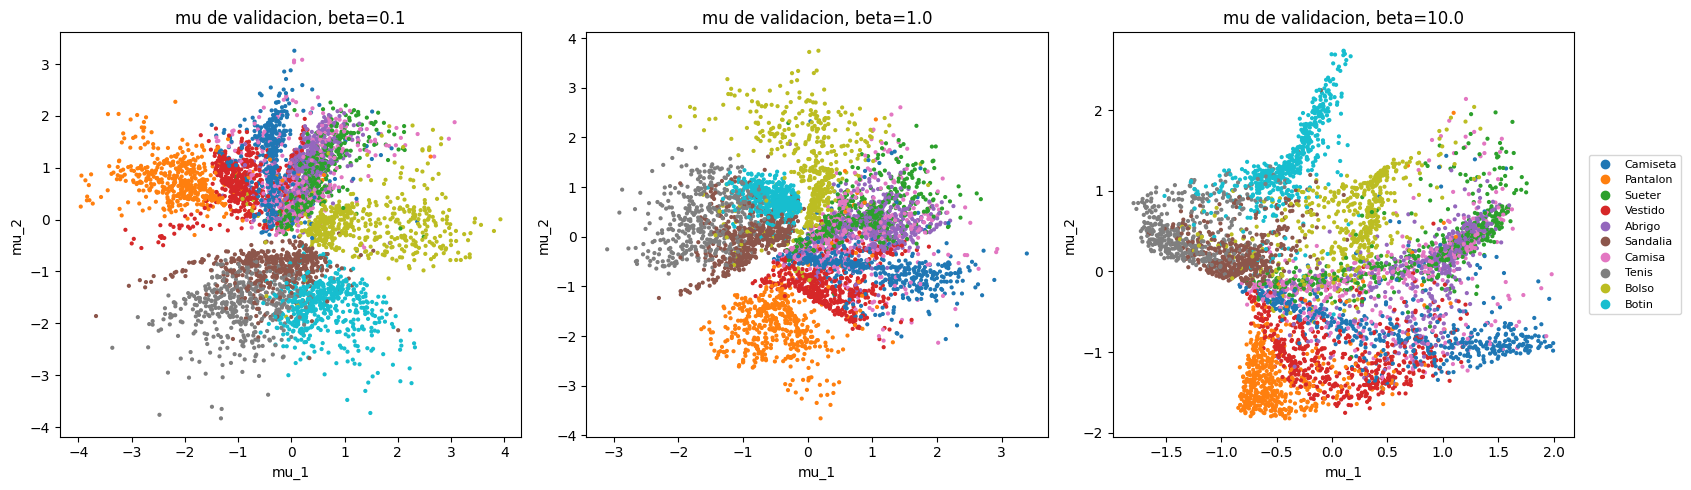

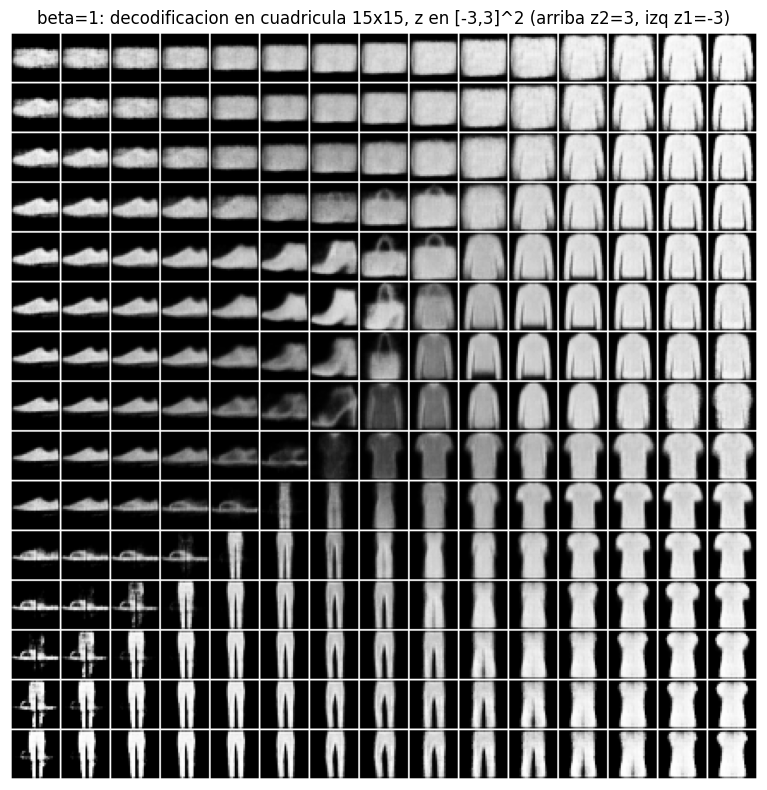

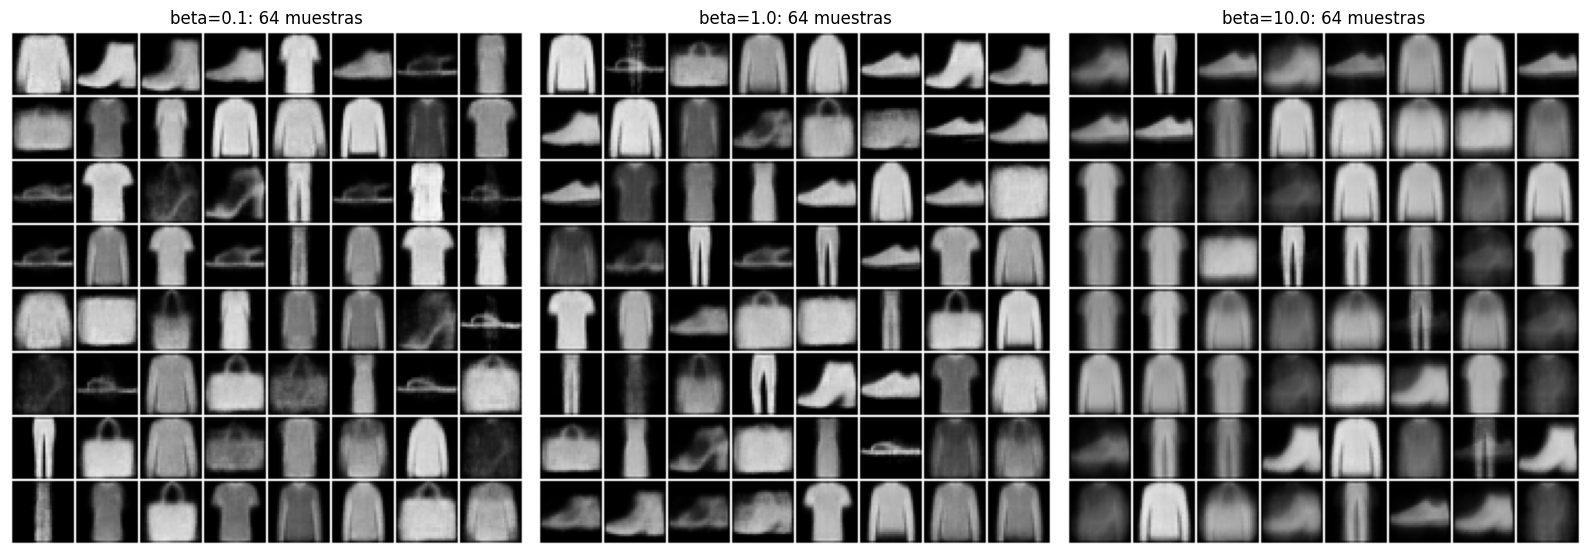

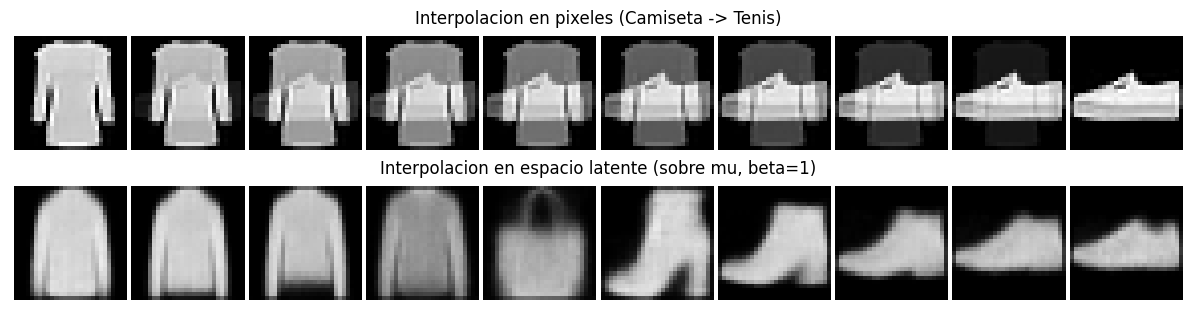

In [3]:
# ---- Task 1.3 ----
with torch.no_grad():
    mus = {b: models[b].encode(Xva)[0] for b in beta_values}
# (a) dispersion de mu coloreada por clase
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for j, b in enumerate(beta_values):
    sc = ax[j].scatter(mus[b][:,0], mus[b][:,1], c=Yva, cmap="tab10", s=4)
    ax[j].set_title(f"mu de validacion, beta={b}"); ax[j].set_xlabel("mu_1"); ax[j].set_ylabel("mu_2")
hd = [plt.Line2D([], [], ls="", marker="o", c=plt.cm.tab10(k)) for k in range(10)]
ax[2].legend(hd, CLASSES, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8)   # leyenda fuera del panel
show("t1_3a_scatter")

# (b) cuadricula 15x15 de z en [-3,3]^2 con beta = 1
lin = torch.linspace(-3, 3, 15)
gz = torch.tensor([[zx, zy] for zy in reversed(lin.tolist()) for zx in lin.tolist()])
with torch.no_grad(): gimg = models[1.0].decode(gz)
plt.figure(figsize=(8, 8)); plt.imshow(to_grid(gimg, 15), cmap="gray")
plt.title("beta=1: decodificacion en cuadricula 15x15, z en [-3,3]^2 (arriba z2=3, izq z1=-3)"); plt.axis("off")
show("t1_3b_grid")

# (c) 64 muestras z ~ N(0,I) por beta
set_seed()
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5)); gen_vae = {}
for j, b in enumerate(beta_values):
    with torch.no_grad(): gen_vae[b] = models[b].decode(torch.randn(64, 2))
    ax[j].imshow(to_grid(gen_vae[b], 8), cmap="gray"); ax[j].set_title(f"beta={b}: 64 muestras"); ax[j].axis("off")
show("t1_3c_muestras")

# (d) interpolacion pixel vs latente (beta=1), clases distintas, 8 puntos intermedios
i1 = int((Yva == 0).nonzero()[0]); i2 = int((Yva == 7).nonzero()[0])
x1, x2 = Xva[i1:i1+1], Xva[i2:i2+1]
al = torch.linspace(0, 1, 10).view(-1, 1, 1, 1)               # extremos + 8 intermedios
pix = (1-al)*x1 + al*x2
with torch.no_grad():
    mu1, mu2 = mus[1.0][i1:i1+1], mus[1.0][i2:i2+1]
    lat = models[1.0].decode((1-al.view(-1,1))*mu1 + al.view(-1,1)*mu2)
fig, ax = plt.subplots(2, 1, figsize=(13, 3.2))
ax[0].imshow(to_grid(pix, 1), cmap="gray"); ax[0].set_title(f"Interpolacion en pixeles ({CLASSES[0]} -> {CLASSES[7]})"); ax[0].axis("off")
ax[1].imshow(to_grid(lat, 1), cmap="gray"); ax[1].set_title("Interpolacion en espacio latente (sobre mu, beta=1)"); ax[1].axis("off")
show("t1_3d_interp")

In [4]:
# ---- Task 1.4 ----
# (a) tabla recon / KL final de validacion
print("beta | recon(val) | KL nats | KL bits | log2(10)=%.2f" % math.log2(10))
R["t1_4a"] = {}
for b in beta_values:
    rec, kl = hists[b]["rec"][-1], hists[b]["kl"][-1]
    R["t1_4a"][str(b)] = dict(rec=rec, kl_nats=kl, kl_bits=kl/math.log(2))
    print(f"{b:>4} | {rec:9.2f}  | {kl:7.3f} | {kl/math.log(2):7.3f}")

# (b) KL cerrada vs Monte Carlo (beta=1, una imagen de validacion)
x = Xva[:1]
with torch.no_grad(): mu, lv = models[1.0].encode(x)
mu, sig = mu.double(), torch.exp(0.5*lv).double()
kl_cf = kl_closed(mu, torch.log(sig**2)).item()
N = 100_000; g = torch.Generator().manual_seed(SEED)
z = mu + sig * torch.randn(N, 2, generator=g, dtype=torch.float64)
logq = (-0.5*math.log(2*math.pi) - torch.log(sig) - 0.5*((z-mu)/sig)**2).sum(1)    # log q(z|x)
logp = (-0.5*math.log(2*math.pi) - 0.5*z**2).sum(1)                                # log p(z)
d = logq - logp; kl_mc = d.mean().item(); se = (d.std()/math.sqrt(N)).item()
R["t1_4b"] = dict(mu=mu.tolist(), sigma=sig.tolist(), kl_closed=kl_cf, kl_mc=kl_mc, rel_err=abs(kl_mc-kl_cf)/kl_cf,
                  std_err_mc=se, z_score=abs(kl_mc-kl_cf)/se)
print(R["t1_4b"])

# (c) evidencia numerica de regiones sin datos + puntos medios de las interpolaciones
dmin = torch.cdist(gz, mus[1.0]).min(1).values            # distancia de cada punto de la malla al mu mas cercano
sh_grid = torch.tensor([sharpness(gimg[i:i+1]) for i in range(len(gimg))])
far = dmin > 1.0
R["t1_4c"] = dict(frac_far=far.float().mean().item(), sharp_far=sh_grid[far].mean().item(), sharp_near=sh_grid[~far].mean().item(),
                  dmin_center=dmin[112].item(), dmin_corners=[dmin[0].item(), dmin[14].item(), dmin[210].item(), dmin[224].item()])
with torch.no_grad():
    mid_pix = 0.5*x1 + 0.5*x2
    mid_lat = models[1.0].decode(0.5*(mu1+mu2))
def nearest_val_dist(im): return torch.cdist(im.flatten(1), Xva.flatten(1)).min().item()
R["t1_4c"].update(sharp_mid_pix=sharpness(mid_pix), sharp_mid_lat=sharpness(mid_lat),
                  nn_dist_mid_pix=nearest_val_dist(mid_pix), nn_dist_mid_lat=nearest_val_dist(mid_lat),
                  sharp_ends=[sharpness(x1), sharpness(x2)])
print(R["t1_4c"])

# (d) nitidez: 1000 reales vs 1000 generadas por beta
set_seed()
R["t1_4d"] = {"real": sharpness(Xva[:1000])}
for b in beta_values:
    with torch.no_grad(): g1000 = models[b].decode(torch.randn(1000, 2))
    R["t1_4d"][str(b)] = sharpness(g1000)
print(R["t1_4d"])

beta | recon(val) | KL nats | KL bits | log2(10)=3.32
 0.1 |     20.53  |   7.728 |  11.150
 1.0 |     21.91  |   4.914 |   7.090
10.0 |     37.61  |   1.598 |   2.305
{'mu': [[1.6994620561599731, 0.12296699732542038]], 'sigma': [[0.18162745237350464, 0.0967247486114502]], 'kl_closed': 4.514501817788226, 'kl_mc': 4.510622293086415, 'rel_err': 0.0008593472454754914, 'std_err_mc': 0.003260687117759557, 'z_score': 1.1897874778234048}
{'frac_far': 0.057777777314186096, 'sharp_far': 0.09742879867553711, 'sharp_near': 0.06253711134195328, 'dmin_center': 0.01668817177414894, 'dmin_corners': [1.0519169569015503, 1.5237091779708862, 1.690224051475525, 1.2762771844863892], 'sharp_mid_pix': 0.07233374565839767, 'sharp_mid_lat': 0.053974274545907974, 'nn_dist_mid_pix': 6.455313205718994, 'nn_dist_mid_lat': 4.080032825469971, 'sharp_ends': [0.11343500018119812, 0.037011101841926575]}


{'real': 0.08914583176374435, '0.1': 0.046270404011011124, '1.0': 0.04951193928718567, '10.0': 0.045885488390922546}


## Task 2 — Proceso forward de difusión

In [5]:
# ---- Task 2.1: calendario lineal y forward cerrado (imagenes en [-1,1]) ----
T, beta_start, beta_end = 1000, 1e-4, 0.02
Xtr2 = Xtr*2 - 1; Xva2 = Xva*2 - 1                       # a [-1,1]
betas = torch.linspace(beta_start, beta_end, T, dtype=torch.float64)   # beta_t, t=1..T (indice t-1)
alphas = 1 - betas                                       # alpha_t = 1 - beta_t
abar = torch.cumprod(alphas, 0)                          # abar_t = prod_{s<=t} alpha_s
betas_f, alphas_f, abar_f = betas.float(), alphas.float(), abar.float()

def q_sample(x0, t, eps, ab=None):
    # x_t = sqrt(abar_t) x0 + sqrt(1-abar_t) eps ;  t entero en 1..T (1-based)
    ab = (abar_f if ab is None else ab)[t-1].view(-1, 1, 1, 1)
    return ab.sqrt()*x0 + (1-ab).sqrt()*eps
print("abar_T =", abar[-1].item())

abar_T = 4.0358297653756754e-05


In [6]:
# ---- Task 2.2: verificacion empirica de la formula cerrada ----
set_seed()
x0 = Xtr2[0:1].double(); n_copies, t_end = 5000, 300
xs = x0.repeat(n_copies, 1, 1, 1)
for s in range(t_end):                                   # x_s = sqrt(alpha_s) x_{s-1} + sqrt(beta_s) eps_s  (ruido nuevo por paso y copia)
    xs = alphas[s].sqrt()*xs + betas[s].sqrt()*torch.randn_like(xs)
emp_mean, emp_var = xs.mean(0), xs.var(0)               # por pixel
th_mean, th_var = abar[t_end-1].sqrt()*x0[0], 1 - abar[t_end-1]
err_mean = (emp_mean - th_mean).abs()
se_mean = (th_var / n_copies).sqrt()                     # error estandar teorico de un promedio de 5000
R["t2_2"] = dict(abar300=abar[t_end-1].item(), max_abs_err_mean=err_mean.max().item(), mean_abs_err_mean=err_mean.mean().item(),
                 se_mean=se_mean.item(), max_err_over_se=(err_mean.max()/se_mean).item(), frac_within_2se=(err_mean < 2*se_mean).double().mean().item(),
                 mean_emp_var=emp_var.mean().item(), th_var=th_var.item(), var_rel_err=abs(emp_var.mean().item()-th_var.item())/th_var.item(),
                 se_var=(th_var*math.sqrt(2/(n_copies-1))).item())
print(R["t2_2"])

{'abar300': 0.39641975945825253, 'max_abs_err_mean': 0.03396385316010697, 'mean_abs_err_mean': 0.008301200055260144, 'se_mean': 0.01098708551474637, 'max_err_over_se': 3.0912522811005907, 'frac_within_2se': 0.9642857142857143, 'mean_emp_var': 0.6037230964023774, 'th_var': 0.6035802405417474, 'var_rel_err': 0.00023668081066038175, 'se_var': 0.012072812152420289}


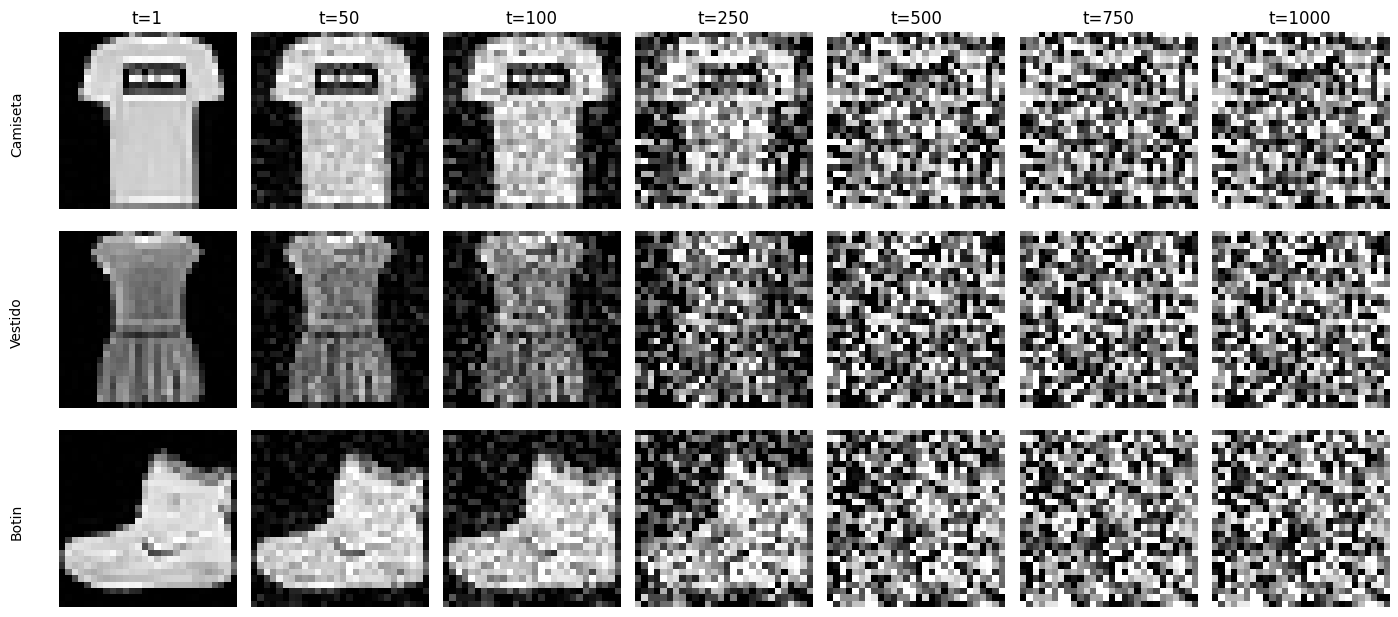

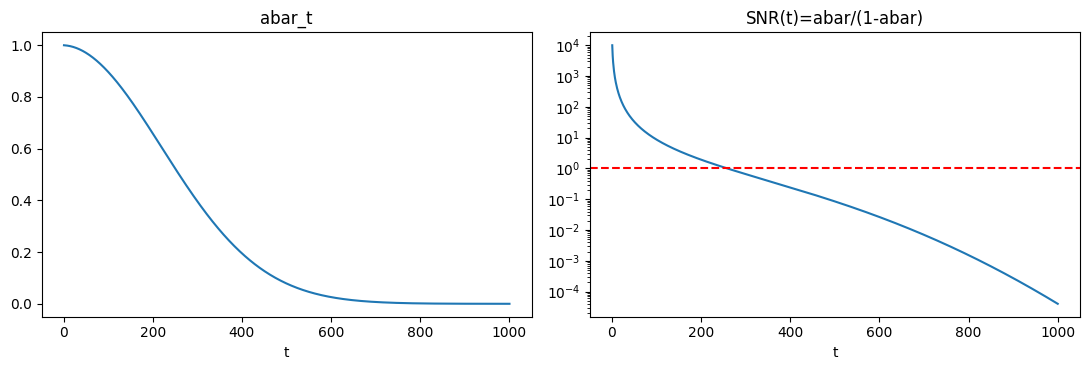

{'first_snr_lt1': 260, 'first_abar_lt001': 674}


In [7]:
# ---- Task 2.3 ----
snr = abar / (1 - abar)
t_list = [1, 50, 100, 250, 500, 750, 1000]
cls3 = [0, 3, 9]
set_seed()
fig, ax = plt.subplots(3, len(t_list), figsize=(14, 6.4))
for r, c in enumerate(cls3):
    x0c = Xtr2[(Ytr == c).nonzero()[0]]; e = torch.randn_like(x0c)         # mismo eps para todos los t
    for j, t in enumerate(t_list):
        xt = q_sample(x0c, torch.tensor([t]), e)
        ax[r, j].imshow(xt[0, 0].clamp(-1, 1), cmap="gray", vmin=-1, vmax=1); ax[r, j].axis("off")
        if r == 0: ax[r, j].set_title(f"t={t}")
    ax[r, 0].text(-6, 14, CLASSES[c], rotation=90, va="center", ha="right")
show("t2_3a_xt")

def first_t(mask): return int(torch.argmax(mask.int()).item()) + 1
R["t2_3c"] = dict(first_snr_lt1=first_t(snr < 1), first_abar_lt001=first_t(abar < 0.01))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(range(1, T+1), abar); ax[0].set_title("abar_t"); ax[0].set_xlabel("t")
ax[1].semilogy(range(1, T+1), snr); ax[1].axhline(1, c="r", ls="--"); ax[1].set_title("SNR(t)=abar/(1-abar)"); ax[1].set_xlabel("t")
show("t2_3b_abar_snr")
print(R["t2_3c"])

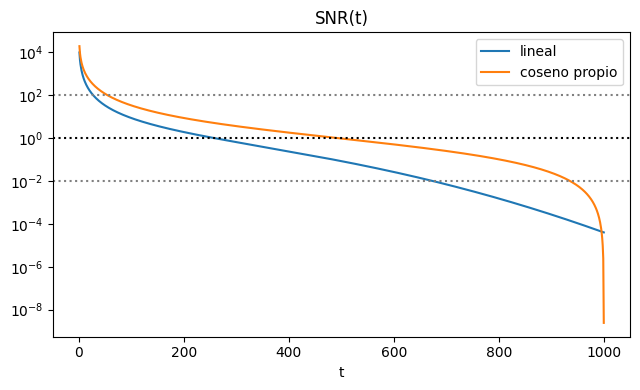

{'lineal': {'abar_T': 4.0358297653756754e-05, 'first_snr_lt1': 260}, 'coseno': {'abar_T': 2.4193667459977043e-09, 'first_snr_lt1': 496}}


In [8]:
# ---- Task 2.4: calendario propio (coseno de Nichol & Dhariwal 2021, modificado: s=0.01, beta_max=0.999 y T=1000) ----
def cosine_schedule(T, s=0.01, max_beta=0.999):
    tt = torch.arange(T+1, dtype=torch.float64) / T
    f = torch.cos((tt + s)/(1 + s) * math.pi/2) ** 2          # abar(t) ~ cos^2
    ab = f / f[0]
    b = (1 - ab[1:]/ab[:-1]).clamp(1e-6, max_beta)            # beta_t en (0,1)
    return b
betas_c = cosine_schedule(T); abar_c = torch.cumprod(1 - betas_c, 0); snr_c = abar_c/(1 - abar_c)
assert abar_c[-1] < 1e-3 and (betas_c > 0).all() and (betas_c < 1).all()
R["t2_4"] = dict(lineal=dict(abar_T=abar[-1].item(), first_snr_lt1=first_t(snr < 1)),
                 coseno=dict(abar_T=abar_c[-1].item(), first_snr_lt1=first_t(snr_c < 1)))
plt.figure(figsize=(6.5, 4)); plt.semilogy(range(1, T+1), snr, label="lineal"); plt.semilogy(range(1, T+1), snr_c, label="coseno propio")
plt.axhline(1, c="k", ls=":"); plt.axhline(0.01, c="gray", ls=":"); plt.axhline(100, c="gray", ls=":"); plt.legend(); plt.xlabel("t"); plt.title("SNR(t)")
show("t2_4_snr"); print(R["t2_4"])

In [9]:
# ---- Task 2.5 ----
# (a) aproximacion a mano de log abar_T para el calendario lineal
S1 = T*(beta_start + beta_end)/2                                              # suma aritmetica de beta_t
S2 = T*(beta_end**3 - beta_start**3) / (3*(beta_end - beta_start))             # sum beta_t^2 ~ integral (progresion lineal)
approx_log = -S1 - 0.5*S2
R["t2_5a"] = dict(S1=S1, S2=S2, log_abar_approx=approx_log, abar_approx=math.exp(approx_log),
                  log_abar_num=math.log(abar[-1].item()), abar_num=abar[-1].item(),
                  S1_exact=betas.sum().item(), S2_exact=(betas**2).sum().item())
print(R["t2_5a"])
# (b) numero de pasos con SNR en [0.01, 100]
cnt = lambda s: int(((s >= 0.01) & (s <= 100)).sum())
R["t2_5b"] = dict(lineal=cnt(snr), coseno=cnt(snr_c),
                  lineal_lt001=int((snr < 0.01).sum()), lineal_gt100=int((snr > 100).sum()),
                  coseno_lt001=int((snr_c < 0.01).sum()), coseno_gt100=int((snr_c > 100).sum()))
print(R["t2_5b"])
# (c) varianza global de x_t = abar Var(x0) + (1-abar)
set_seed()
var0 = Xtr2.var(unbiased=False).item(); R["t2_5c"] = {"var_x0": var0}
for t in [1, 250, 500, 1000]:
    e = torch.randn_like(Xtr2); xt = q_sample(Xtr2, torch.full((len(Xtr2),), t), e)
    R["t2_5c"][t] = dict(emp=xt.var(unbiased=False).item(), pred=(abar[t-1]*var0 + 1 - abar[t-1]).item())
    del e, xt
print(R["t2_5c"])

{'S1': 10.05, 'S2': 0.13400333333333336, 'log_abar_approx': -10.117001666666667, 'abar_approx': 4.038703797557933e-05, 'log_abar_num': -10.117713542413107, 'abar_num': 4.0358297653756754e-05, 'S1_exact': 10.05, 'S2_exact': 0.1340694010677344}
{'lineal': 647, 'coseno': 881, 'lineal_lt001': 326, 'lineal_gt100': 27, 'coseno_lt001': 65, 'coseno_gt100': 54}


{'var_x0': 0.49825870990753174, 1: {'emp': 0.4983040988445282, 'pred': 0.49830888403654106}, 250: {'emp': 0.7372262477874756, 'pred': 0.73704472841827}, 500: {'emp': 0.9603426456451416, 'pred': 0.9605695353716865}, 1000: {'emp': 1.0003905296325684, 'pred': 0.9999797505756691}}


## Task 3 — Difusión condicional con guía sin clasificador

In [10]:
# ---- Task 3.1: U-Net condicional ----
def sinusoidal_embedding(t, dim):
    # positional encoding (Semana 6): PE(pos,2i)=sin(pos/10000^(2i/d)), PE(pos,2i+1)=cos(pos/10000^(2i/d))
    i = torch.arange(dim//2, device=t.device)
    freqs = torch.exp(-math.log(10000.0) * (2*i/dim))
    ang = t.float()[:, None] * freqs[None]
    emb = torch.zeros(len(t), dim, device=t.device)
    emb[:, 0::2] = torch.sin(ang); emb[:, 1::2] = torch.cos(ang)
    return emb

class ResBlock(nn.Module):
    def __init__(self, cin, cout, edim):
        super().__init__()
        self.n1 = nn.GroupNorm(8, cin); self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.proj = nn.Linear(edim, cout)                       # inyecta (t + clase) con broadcasting
        self.n2 = nn.GroupNorm(8, cout); self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, emb):
        h = self.c1(F.silu(self.n1(x)))
        h = h + self.proj(F.silu(emb))[:, :, None, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)

class UNet(nn.Module):
    def __init__(self, ed=128, nclass=11):
        super().__init__()
        self.ed = ed
        self.tmlp = nn.Sequential(nn.Linear(ed, ed), nn.SiLU(), nn.Linear(ed, ed))
        self.cemb = nn.Embedding(nclass, ed)                     # clase 10 = condicion nula
        self.inc = nn.Conv2d(1, 32, 3, padding=1)
        self.enc1 = ResBlock(32, 32, ed)                         # 28x28, 32 canales
        self.down = nn.Conv2d(32, 32, 3, stride=2, padding=1)    # 28 -> 14
        self.enc2 = ResBlock(32, 64, ed)                         # 14x14, 64 canales
        self.mid1 = ResBlock(64, 64, ed); self.mid2 = ResBlock(64, 64, ed)   # cuello de botella 14x14
        self.dec2 = ResBlock(128, 64, ed)                        # concat skip (64+64)
        self.up = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(64, 32, 3, padding=1))
        self.dec1 = ResBlock(64, 32, ed)                         # concat skip (32+32)
        self.out = nn.Sequential(nn.GroupNorm(8, 32), nn.SiLU(), nn.Conv2d(32, 1, 3, padding=1))
    def forward(self, x, t, c):
        emb = self.tmlp(sinusoidal_embedding(t, self.ed)) + self.cemb(c)
        s1 = self.enc1(self.inc(x), emb)
        s2 = self.enc2(self.down(s1), emb)
        b = self.mid2(self.mid1(s2, emb), emb)
        u = self.dec2(torch.cat([b, s2], 1), emb)
        u = self.dec1(torch.cat([self.up(u), s1], 1), emb)
        return self.out(u)

NULL = 10
set_seed(); unet = UNet()
R["t3_1"] = dict(params=sum(p.numel() for p in unet.parameters()))
print("parametros:", R["t3_1"]["params"], "| salida:", unet(torch.randn(2,1,28,28), torch.tensor([5, 900]), torch.tensor([3, 10])).shape)

parametros: 478017 | salida: torch.Size([2, 1, 28, 28])


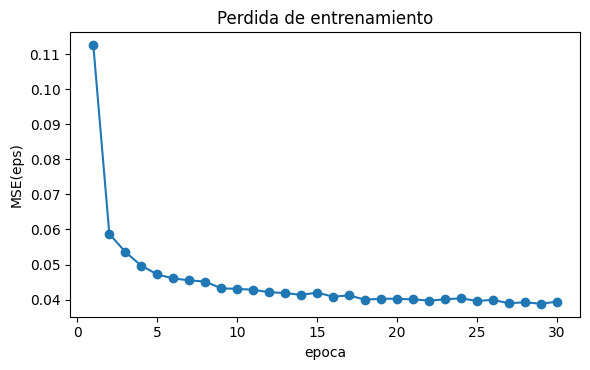

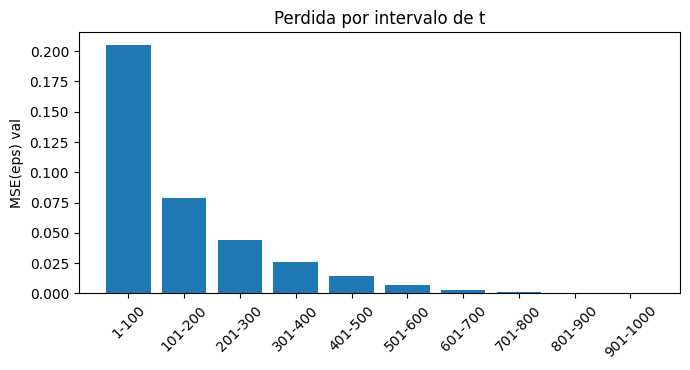

[0.2053, 0.079, 0.0445, 0.0263, 0.0146, 0.007, 0.0027, 0.0009, 0.0003, 0.0001]


In [11]:
# ---- Task 3.2: entrenamiento ----
EP_DIFF = 1 if FAST else 30; bs_d, lr_d, p_uncond = 128, 2e-4, 0.1
path = f"{CK}/ddpm.pt"
model_d = UNet(); ema = copy.deepcopy(model_d); opt = torch.optim.Adam(model_d.parameters(), lr=lr_d)
hist_d = {"loss": [], "time": []}; start = 0; nstep = 0
set_seed()
if os.path.exists(path):
    d = torch.load(path, weights_only=False)
    model_d.load_state_dict(d["sd"]); ema.load_state_dict(d["ema"]); opt.load_state_dict(d["opt"])
    hist_d = d["hist"]; start = d["ep"]; nstep = d["nstep"]
for ep in range(start, EP_DIFF):
    set_seed(SEED + ep); model_d.train(); perm = torch.randperm(len(Xtr2)); tot = 0.; nb = 0; t0 = time.time()
    for i in range(0, len(Xtr2), bs_d):
        idx = perm[i:i+bs_d]; x0b, cb = Xtr2[idx], Ytr[idx].clone()
        t = torch.randint(1, T+1, (len(idx),))                    # t ~ U{1..T}
        eps = torch.randn_like(x0b)                               # eps ~ N(0,I)
        xt = q_sample(x0b, t, eps)                                # forward cerrado (Task 2.1)
        cb[torch.rand(len(idx)) < p_uncond] = NULL                # condicion nula con prob. p_uncond
        loss = F.mse_loss(model_d(xt, t, cb), eps)                # ||eps - eps_theta||^2
        opt.zero_grad(); loss.backward(); opt.step(); nstep += 1
        dcy = min(0.999, (1 + nstep)/(10 + nstep))                # EMA de pesos (para muestrear)
        with torch.no_grad():
            for pe, p in zip(ema.parameters(), model_d.parameters()): pe.mul_(dcy).add_(p.detach(), alpha=1-dcy)
        tot += loss.item(); nb += 1
    hist_d["loss"].append(tot/nb); hist_d["time"].append(time.time()-t0)
    print(f"ep{ep+1:02d} loss={tot/nb:.4f} ({hist_d['time'][-1]:.0f}s)", flush=True)
    torch.save(dict(sd=model_d.state_dict(), ema=ema.state_dict(), opt=opt.state_dict(), hist=hist_d, ep=ep+1, nstep=nstep), path)
ema.eval(); model_d.eval()
plt.figure(figsize=(6, 3.8)); plt.plot(range(1, len(hist_d["loss"])+1), hist_d["loss"], "o-"); plt.xlabel("epoca"); plt.ylabel("MSE(eps)"); plt.title("Perdida de entrenamiento")
show("t3_2_loss")

# perdida de validacion por intervalo de t (10 intervalos de 100 pasos), modelo EMA, clase verdadera
set_seed(); L = []
with torch.no_grad():
    for k in range(10):
        tot = 0.
        for rep in range(2):
            for i in range(0, 5000, 1000):
                x0b, cb = Xva2[i:i+1000], Yva[i:i+1000]
                t = torch.randint(100*k+1, 100*k+101, (len(x0b),)); eps = torch.randn_like(x0b)
                tot += F.mse_loss(ema(q_sample(x0b, t, eps), t, cb), eps).item() * len(x0b)
        L.append(tot / (2*5000))
R["t3_2_interval_loss"] = L
plt.figure(figsize=(7, 3.8)); plt.bar([f"{100*k+1}-{100*k+100}" for k in range(10)], L); plt.xticks(rotation=45); plt.ylabel("MSE(eps) val"); plt.title("Perdida por intervalo de t")
show("t3_2_interval"); print([round(v, 4) for v in L])

w=7: 3171s


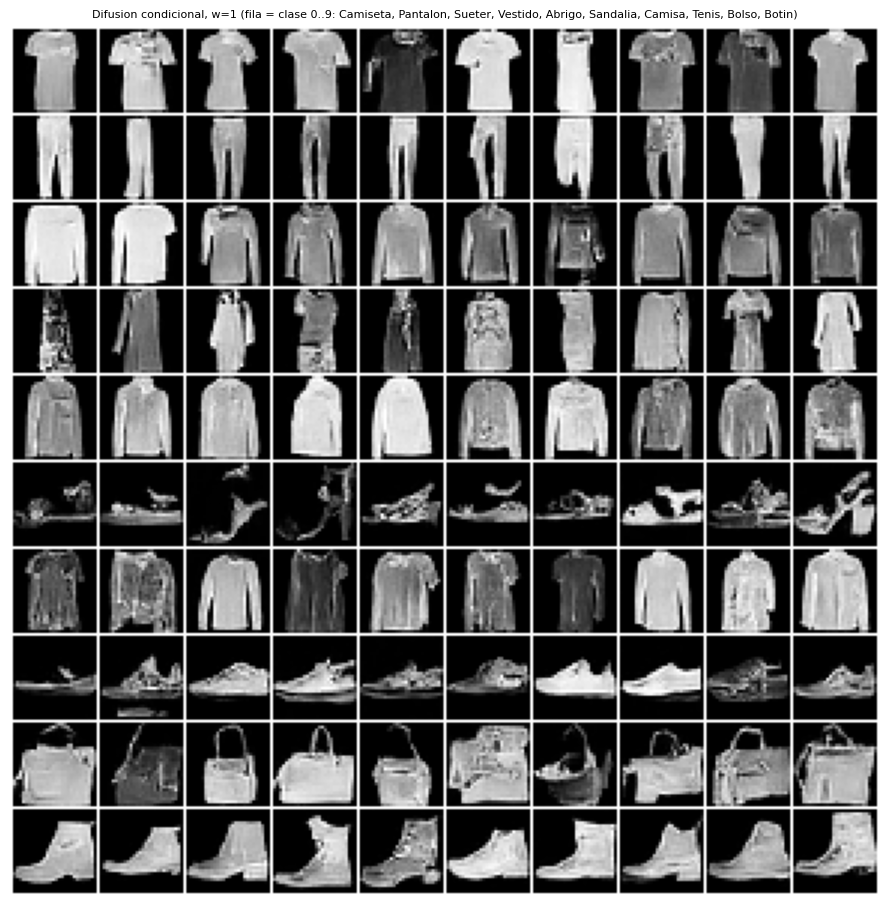

In [12]:
# ---- Task 3.3 / 3.4: muestreo ancestral con guia sin clasificador ----
@torch.no_grad()
def sample(model, labels, w=1.0):
    # x_{t-1} = 1/sqrt(alpha_t) (x_t - (1-alpha_t)/sqrt(1-abar_t) eps~) + sqrt(beta_t) z ,  z=0 en t=1
    # eps~ = eps(x,t,null) + w (eps(x,t,c) - eps(x,t,null))   (w=1 -> condicional puro)
    N = len(labels); x = torch.randn(N, 1, 28, 28); nul = torch.full_like(labels, NULL)
    for t in range(T, 0, -1):
        tt = torch.full((N,), t)
        if w == 1:
            eps_hat = model(x, tt, labels)
        else:
            e_c, e_u = model(torch.cat([x, x]), torch.cat([tt, tt]), torch.cat([labels, nul])).chunk(2)
            eps_hat = e_u + w*(e_c - e_u)
        mean = (x - betas_f[t-1]/(1 - abar_f[t-1]).sqrt()*eps_hat) / alphas_f[t-1].sqrt()
        x = mean + (betas_f[t-1].sqrt()*torch.randn_like(x) if t > 1 else 0.)
    return x.clamp(-1, 1)

NPC = 3 if FAST else 50                                         # imagenes por clase para Task 3.4
gen, gen_time = {}, {}
for w in [1, 3, 7]:
    p = f"{CK}/gen_w{w}.pt"
    if os.path.exists(p):
        d = torch.load(p, weights_only=False); gen[w], gen_time[w] = d["x"], d["t"]; continue
    set_seed(SEED + w); labels = torch.arange(10).repeat_interleave(NPC)
    t0 = time.time(); gen[w] = sample(ema, labels, w); gen_time[w] = time.time() - t0
    torch.save(dict(x=gen[w], t=gen_time[w]), p); print(f"w={w}: {gen_time[w]:.0f}s", flush=True)
labels_g = torch.arange(10).repeat_interleave(NPC)

# Task 3.3: 10 por clase con w=1 (primeras 10 de las generadas), una fila por clase
sel = torch.cat([gen[1][c*NPC:c*NPC+min(10, NPC)] for c in range(10)])
plt.figure(figsize=(9, 9.5)); plt.imshow(to_grid(sel, 10, lo=-1, hi=1), cmap="gray"); plt.axis("off")
plt.title("Difusion condicional, w=1 (fila = clase 0..9: " + ", ".join(CLASSES) + ")", fontsize=8)
show("t3_3_samples")

clf ep1 val acc=0.8658


clf ep2 val acc=0.8846


exactitud del clasificador (val): 0.8845999836921692


w | fidelidad | diversidad | seg/100 img
1 | 0.872 | 16.15 | 306.2
3 | 0.984 | 14.09 | 641.6
7 | 1.000 | 13.97 | 634.1
real | diversidad 17.5


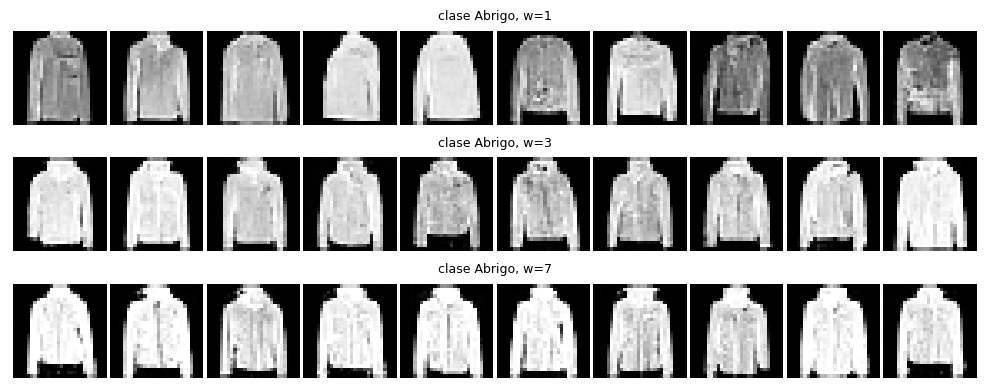

In [13]:
# ---- Task 3.4(c): clasificador sencillo ----
class Clf(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Flatten(), nn.Linear(64*7*7,128), nn.ReLU(), nn.Linear(128,10))
    def forward(self, x): return self.net(x)
set_seed(); clf = Clf(); optc = torch.optim.Adam(clf.parameters(), lr=1e-3); pc = f"{CK}/clf.pt"
if os.path.exists(pc): clf.load_state_dict(torch.load(pc, weights_only=False))
else:
    for ep in range(15):
        clf.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 128):
            idx = perm[i:i+128]; l = F.cross_entropy(clf(Xtr[idx]), Ytr[idx]); optc.zero_grad(); l.backward(); optc.step()
        clf.eval()
        with torch.no_grad(): acc = (clf(Xva).argmax(1) == Yva).float().mean().item()
        print(f"clf ep{ep+1} val acc={acc:.4f}")
        if acc >= 0.88: break
    torch.save(clf.state_dict(), pc)
clf.eval()
with torch.no_grad(): R["clf_val_acc"] = (clf(Xva).argmax(1) == Yva).float().mean().item()
print("exactitud del clasificador (val):", R["clf_val_acc"])
@torch.no_grad()
def classify(x): return clf((x + 1)/2).argmax(1)               # x en [-1,1] -> [0,1]

def diversity_per_class(x, labels):
    out = []
    for c in range(10):
        xc = x[labels == c].flatten(1)
        out.append(torch.pdist(xc).mean().item())               # distancia euclidiana media entre pares
    return out

# referencia real: 50 por clase del entrenamiento
real_idx = torch.cat([(Ytr == c).nonzero().flatten()[:NPC] for c in range(10)])
real_x, real_y = Xtr2[real_idx], Ytr[real_idx]
div_real = diversity_per_class(real_x, real_y)
R["t3_4"] = {"real": dict(div_global=float(np.mean(div_real)), div_per_class=div_real)}
for w in [1, 3, 7]:
    pred = classify(gen[w]); dv = diversity_per_class(gen[w], labels_g)
    R["t3_4"][str(w)] = dict(fidelity=(pred == labels_g).float().mean().item(), fid_per_class=[(pred[labels_g==c]==c).float().mean().item() for c in range(10)],
                             div_global=float(np.mean(dv)), div_per_class=dv, time_total=gen_time[w], time_per_100=gen_time[w]/(len(labels_g)/100))
print("w | fidelidad | diversidad | seg/100 img");
for w in [1, 3, 7]:
    r = R["t3_4"][str(w)]; print(f"{w} | {r['fidelity']:.3f} | {r['div_global']:.2f} | {r['time_per_100']:.1f}")
print("real | diversidad", round(R["t3_4"]["real"]["div_global"], 2))

# figura: 10 muestras de la clase cuya diversidad cae mas entre w=1 y w=7 (eleccion propia, justificada)
drop = np.array(R["t3_4"]["1"]["div_per_class"]) - np.array(R["t3_4"]["7"]["div_per_class"]); cstar = int(drop.argmax()); R["t3_5a_class"] = cstar
fig, ax = plt.subplots(3, 1, figsize=(10, 4))
for r, w in enumerate([1, 3, 7]):
    ax[r].imshow(to_grid(gen[w][labels_g == cstar][:10], 1, lo=-1, hi=1), cmap="gray"); ax[r].axis("off"); ax[r].set_title(f"clase {CLASSES[cstar]}, w={w}", fontsize=9)
show("t3_4d_clase")

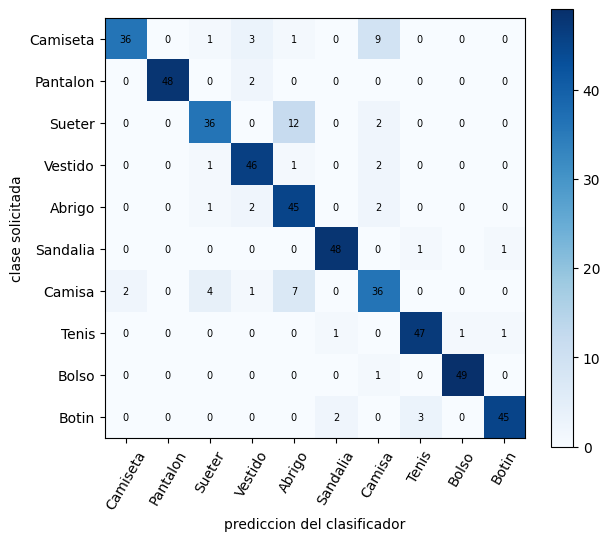

{'confusion': [[36, 0, 1, 3, 1, 0, 9, 0, 0, 0], [0, 48, 0, 2, 0, 0, 0, 0, 0, 0], [0, 0, 36, 0, 12, 0, 2, 0, 0, 0], [0, 0, 1, 46, 1, 0, 2, 0, 0, 0], [0, 0, 1, 2, 45, 0, 2, 0, 0, 0], [0, 0, 0, 0, 0, 48, 0, 1, 0, 1], [2, 0, 4, 1, 7, 0, 36, 0, 0, 0], [0, 0, 0, 0, 0, 1, 0, 47, 1, 1], [0, 0, 0, 0, 0, 0, 1, 0, 49, 0], [0, 0, 0, 0, 0, 2, 0, 3, 0, 45]], 'pair': [2, 4], 'counts': [12, 1]}


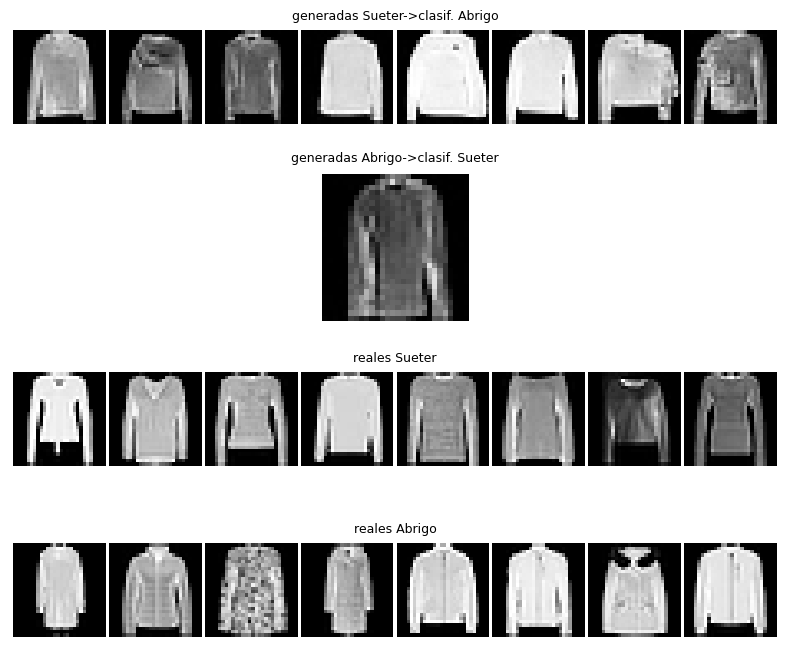

In [14]:
# ---- Task 3.5(b): matriz de confusion (w=1) ----
pred1 = classify(gen[1]); C = torch.zeros(10, 10, dtype=torch.long)
for a, b in zip(labels_g, pred1): C[a, b] += 1
sym = C + C.T; sym.fill_diagonal_(0); i, j = divmod(int(sym.argmax()), 10)
R["t3_5b"] = dict(confusion=C.tolist(), pair=[i, j], counts=[int(C[i, j]), int(C[j, i])])
plt.figure(figsize=(6.5, 5.5)); plt.imshow(C, cmap="Blues"); plt.colorbar()
for a in range(10):
    for b in range(10): plt.text(b, a, int(C[a, b]), ha="center", va="center", fontsize=7)
plt.xticks(range(10), CLASSES, rotation=60); plt.yticks(range(10), CLASSES); plt.xlabel("prediccion del clasificador"); plt.ylabel("clase solicitada")
show("t3_5b_confusion"); print(R["t3_5b"])
# imagenes: generadas de la clase i clasificadas como j (y viceversa) frente a reales
ex_ij = gen[1][(labels_g == i) & (pred1 == j)][:8]; ex_ji = gen[1][(labels_g == j) & (pred1 == i)][:8]
rows = [(f"generadas {CLASSES[i]}->clasif. {CLASSES[j]}", ex_ij), (f"generadas {CLASSES[j]}->clasif. {CLASSES[i]}", ex_ji),
        (f"reales {CLASSES[i]}", Xva2[Yva == i][:8]), (f"reales {CLASSES[j]}", Xva2[Yva == j][:8])]
fig, ax = plt.subplots(4, 1, figsize=(8, 7))
for a, (ttl, im) in zip(ax, rows):
    a.imshow(to_grid(im, 1, lo=-1, hi=1) if len(im) else np.ones((30, 30)), cmap="gray"); a.axis("off"); a.set_title(ttl, fontsize=9)
show("t3_5b_pair")

## Task 4 — Comparación y pass@k

In [15]:
# ---- Task 4.1 ----
# (a) nitidez (todo llevado a [0,1] para ser comparable)
set_seed(SEED + 100)
with torch.no_grad(): vae500 = models[1.0].decode(torch.randn(500, 2))
sel500 = torch.cat([gen[1][c*NPC:(c+1)*NPC][:50] for c in range(10)])
R["t4_1a"] = dict(difusion_w1=sharpness((sel500 + 1)/2), vae_b1=sharpness(vae500), real=sharpness(Xva[:500]))
print(R["t4_1a"])
# (b) tiempo de 100 imagenes
set_seed(); lab100 = torch.arange(10).repeat_interleave(10)
with torch.no_grad():
    t0 = time.time()
    for _ in range(50): models[1.0].decode(torch.randn(100, 2))
    t_vae = (time.time() - t0)/50
t0 = time.time(); _ = sample(ema, lab100, w=1); t_dif = time.time() - t0
R["t4_1b"] = dict(t_vae=t_vae, t_dif=t_dif, ratio=t_dif/t_vae, evals_vae=1, evals_dif=T)
print(R["t4_1b"])

{'difusion_w1': 0.08370418101549149, 'vae_b1': 0.05119362846016884, 'real': 0.08857910335063934}


{'t_vae': 0.007785677909851074, 't_dif': 274.1721193790436, 'ratio': 35214.93215537965, 'evals_vae': 1, 'evals_dif': 1000}


In [16]:
# ---- Task 4.2: pass@k ----
from math import comb
probs = {"P1": (20, 0), "P2": (20, 2), "P3": (20, 5), "P4": (20, 9), "P5": (20, 14), "P6": (20, 20)}
def pass_at_k(n, c, k): return 1.0 if n - c < k else 1 - comb(n-c, k)/comb(n, k)       # insesgado
def naive(n, c, k): return 1 - (1 - c/n)**k
R["t4_2"] = {"pass": {}, "naive5": {}}
print("prob | pass@1 pass@5 pass@10 | ingenuo@5")
for p, (n, c) in probs.items():
    v = [pass_at_k(n, c, k) for k in (1, 5, 10)]; R["t4_2"]["pass"][p] = v; R["t4_2"]["naive5"][p] = naive(n, c, 5)
    print(p, [round(x, 4) for x in v], round(naive(n, c, 5), 4))
R["t4_2"]["mean"] = [float(np.mean([R["t4_2"]["pass"][p][i] for p in probs])) for i in range(3)]
print("promedios:", [round(x, 4) for x in R["t4_2"]["mean"]])
print("P2,k=5: C(18,5)=%d, C(20,5)=%d, razon=%.4f -> pass@5=%.4f" % (comb(18,5), comb(20,5), comb(18,5)/comb(20,5), 1 - comb(18,5)/comb(20,5)))
print("(b) forma cerrada = metodo directo:", all(abs(pass_at_k(20,2,k) - (1 - (20-k)*(19-k)/380)) < 1e-12 for k in range(1, 19)))
print("menor k con pass@k>0.9 en P2:", next(k for k in range(1, 21) if pass_at_k(20, 2, k) > 0.9), [round(pass_at_k(20,2,k), 4) for k in (13, 14)])
R["t4_2"]["k90"] = next(k for k in range(1, 21) if pass_at_k(20, 2, k) > 0.9)
json.dump(R, open(f"results{'_fast' if FAST else ''}.json", "w"), indent=1, default=str)

prob | pass@1 pass@5 pass@10 | ingenuo@5
P1 [0.0, 0.0, 0.0] 0.0
P2 [0.1, 0.4474, 0.7632] 0.4095
P3 [0.25, 0.8063, 0.9837] 0.7627
P4 [0.45, 0.9702, 0.9999] 0.9497
P5 [0.7, 0.9996, 1.0] 0.9976
P6 [1.0, 1.0, 1.0] 1.0
promedios: [0.4167, 0.7039, 0.7911]
P2,k=5: C(18,5)=8568, C(20,5)=15504, razon=0.5526 -> pass@5=0.4474
(b) forma cerrada = metodo directo: True
menor k con pass@k>0.9 en P2: 14 [0.8895, 0.9211]
